In [83]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

print(PROJECT_ROOT)

c:\Users\NIkAt\coding\codes\Machine Learning\ML_Hackathon\PathSnap


In [84]:

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from collections import Counter

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")


Libraries imported successfully!


In [85]:

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

RAW_DIR = PROJECT_ROOT / "data" / "raw"
TRAIN_DIR = RAW_DIR / "train"
TEST_DIR = RAW_DIR / "student_test"

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Training directory:", TRAIN_DIR)
print("Student test directory:", TEST_DIR)
print("Processed directory:", PROCESSED_DIR)

assert TRAIN_DIR.exists(), "Training directory not found!"
assert TEST_DIR.exists(), "Student test directory not found!"

print("\nDirectory setup successful!")


Project root: c:\Users\NIkAt\coding\codes\Machine Learning\ML_Hackathon\PathSnap
Training directory: c:\Users\NIkAt\coding\codes\Machine Learning\ML_Hackathon\PathSnap\data\raw\train
Student test directory: c:\Users\NIkAt\coding\codes\Machine Learning\ML_Hackathon\PathSnap\data\raw\student_test
Processed directory: c:\Users\NIkAt\coding\codes\Machine Learning\ML_Hackathon\PathSnap\data\processed

Directory setup successful!


In [86]:

def get_trip_directories(directory):

    return sorted([
        folder for folder in directory.iterdir()
        if folder.is_dir()
    ])


train_trips = get_trip_directories(TRAIN_DIR)
test_trips = get_trip_directories(TEST_DIR)

print("Number of training trips:", len(train_trips))
print("Number of student testing trips:", len(test_trips))

print("\nFirst 10 training trips:")
for trip in train_trips[:10]:
    print(trip.name)

print("\nStudent testing trips:")
for trip in test_trips:
    print(trip.name)


Number of training trips: 80
Number of student testing trips: 10

First 10 training trips:
00000001
00000002
00000003
00000004
00000005
00000006
00000008
00000010
00000011
00000012

Student testing trips:
00000000
00000007
00000009
00000040
00000052
00000056
00000065
00000076
00000077
00000091


In [87]:

def get_trip_directories(directory):

    return sorted([
        folder for folder in directory.iterdir()
        if folder.is_dir()
    ])


train_trips = get_trip_directories(TRAIN_DIR)
test_trips = get_trip_directories(TEST_DIR)

print("Number of training trips:", len(train_trips))
print("Number of student testing trips:", len(test_trips))

print("\nFirst 10 training trips:")
for trip in train_trips[:10]:
    print(trip.name)

print("\nStudent testing trips:")
for trip in test_trips:
    print(trip.name)


Number of training trips: 80
Number of student testing trips: 10

First 10 training trips:
00000001
00000002
00000003
00000004
00000005
00000006
00000008
00000010
00000011
00000012

Student testing trips:
00000000
00000007
00000009
00000040
00000052
00000056
00000065
00000076
00000077
00000091


In [88]:
print("GPS observations:", track.shape)
print("Road network nodes:", nodes.shape)
print("Road network arcs:", arcs.shape)
print("Reference route length:", route.shape)

print("\nData types:")

print("\nTRACK")
print(track.dtypes)

print("\nNODES")
print(nodes.dtypes)

print("\nARCS")
print(arcs.dtypes)

print("\nROUTE")
print("Data types:")
print(route.dtypes)

print("Shape:", route.shape)
print("Object type:", type(route))

GPS observations: (1315, 4)
Road network nodes: (88809, 3)
Road network arcs: (165790, 3)
Reference route length: (525, 1)

Data types:

TRACK
longitude         float64
latitude          float64
timestamp         float64
observation_id      int64
dtype: object

NODES
longitude    float64
latitude     float64
node_id        int64
dtype: object

ARCS
from_node    int64
to_node      int64
arc_id       int64
dtype: object

ROUTE
Data types:
arc_id    int64
dtype: object
Shape: (525, 1)
Object type: <class 'pandas.core.frame.DataFrame'>


In [89]:

def load_trip(trip_folder):

    trip_id = trip_folder.name

    track = pd.read_csv(
        trip_folder / f"{trip_id}.track",
        sep=r"\s+",
        header=None,
        names=["longitude", "latitude", "timestamp"]
    )

    nodes = pd.read_csv(
        trip_folder / f"{trip_id}.nodes",
        sep=r"\s+",
        header=None,
        names=["longitude", "latitude"]
    )

    arcs = pd.read_csv(
        trip_folder / f"{trip_id}.arcs",
        sep=r"\s+",
        header=None,
        names=["from_node", "to_node"]
    )

    route = pd.read_csv(
        trip_folder / f"{trip_id}.route",
        sep=r"\s+",
        header=None,
        names=["arc_id"]
    )

    # Preserve original row indices.
    track["observation_id"] = np.arange(len(track))
    nodes["node_id"] = np.arange(len(nodes))
    arcs["arc_id"] = np.arange(len(arcs))

    return {
        "trip_id": trip_id,
        "track": track,
        "nodes": nodes,
        "arcs": arcs,
        "route": route
    }


In [90]:

sample_trip = load_trip(TRAIN_DIR / "00000001")

track = sample_trip["track"]
nodes = sample_trip["nodes"]
arcs = sample_trip["arcs"]
route = sample_trip["route"]

print("Trip ID:", sample_trip["trip_id"])

print("\nGPS observations:")
display(track.head())

print("\nRoad network nodes:")
display(nodes.head())

print("\nRoad network arcs:")
display(arcs.head())

print("\nReference route:")
display(route.head())


Trip ID: 00000001

GPS observations:


,longitude,latitude,timestamp,observation_id
0,8.595203,49.844053,1.0,0
1,8.595294,49.844441,2.0,1
2,8.595352,49.844883,3.0,2
3,8.595390,49.845379,4.0,3
4,8.595587,49.845750,5.0,4



Road network nodes:


,longitude,latitude,node_id
0,8.581679,49.857880,0
1,8.584637,49.858295,1
2,8.580173,49.858567,2
3,8.584392,49.859119,3
4,8.584935,49.857396,4



Road network arcs:


,from_node,to_node,arc_id
0,0,281,0
1,0,1,1
2,0,5,2
3,1,0,3
4,1,40750,4



Reference route:


,arc_id
0,2641
1,64973
2,133948
3,133949
4,139208


In [91]:

print("GPS observations:", track.shape)
print("Road network nodes:", nodes.shape)
print("Road network arcs:", arcs.shape)
print("Reference route length:", route.shape)

print("\nData types:")
print("\nTRACK")
print(track.dtypes)

print("\nNODES")
print(nodes.dtypes)

print("\nARCS")
print(arcs.dtypes)

print("\nROUTE")
print(route.dtypes)


GPS observations: (1315, 4)
Road network nodes: (88809, 3)
Road network arcs: (165790, 3)
Reference route length: (525, 1)

Data types:

TRACK
longitude         float64
latitude          float64
timestamp         float64
observation_id      int64
dtype: object

NODES
longitude    float64
latitude     float64
node_id        int64
dtype: object

ARCS
from_node    int64
to_node      int64
arc_id       int64
dtype: object

ROUTE
arc_id    int64
dtype: object


In [92]:

def inspect_track(track):

    df = track.copy()

    print("Total observations:", len(df))

    print("\nMissing values:")
    display(df.isnull().sum())

    print("\nDuplicate rows:", df.duplicated().sum())

    print("\nLongitude statistics:")
    display(df["longitude"].describe())

    print("\nLatitude statistics:")
    display(df["latitude"].describe())

    print("\nTimestamp statistics:")
    display(df["timestamp"].describe())

    invalid_coordinates = (
        ~df["longitude"].between(-180, 180) |
        ~df["latitude"].between(-90, 90)
    )

    print("\nInvalid coordinate rows:", invalid_coordinates.sum())

    time_diff = df["timestamp"].diff()

    print("\nTimestamp difference distribution:")
    display(time_diff.value_counts().head(10))

    print("\nNon-increasing timestamps:", (time_diff <= 0).sum())

    return time_diff


time_diff = inspect_track(track)


Total observations: 1315

Missing values:


longitude         0
latitude          0
timestamp         0
observation_id    0
dtype: int64


Duplicate rows: 0

Longitude statistics:


count    1315.000000
mean        8.605599
std         0.016356
min         8.570524
25%         8.596061
50%         8.603564
75%         8.612624
max         8.647860
Name: longitude, dtype: float64


Latitude statistics:


count    1315.000000
mean       50.088368
std         0.117561
min        49.844053
25%        49.987136
50%        50.128292
75%        50.199064
max        50.211882
Name: latitude, dtype: float64


Timestamp statistics:


count    1315.000000
mean      661.000760
std       384.387699
min         1.000000
25%       329.500000
50%       658.000000
75%       988.500000
max      1358.000000
Name: timestamp, dtype: float64


Invalid coordinate rows: 0

Timestamp difference distribution:


timestamp
1.0     1289
2.0       21
3.0        2
16.0       1
4.0        1
Name: count, dtype: int64


Non-increasing timestamps: 0


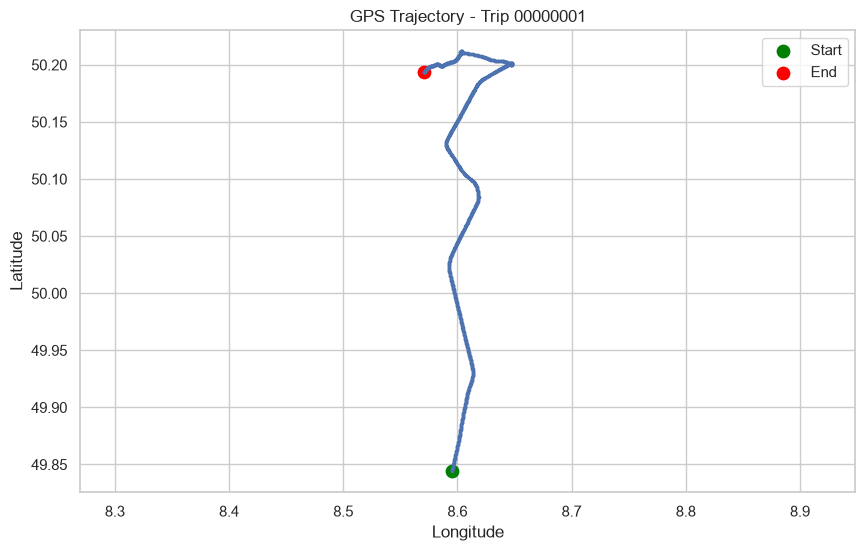

In [93]:

plt.figure(figsize=(10, 6))

plt.plot(
    track["longitude"],
    track["latitude"],
    marker=".",
    markersize=3,
    linewidth=1
)

plt.scatter(
    track["longitude"].iloc[0],
    track["latitude"].iloc[0],
    color="green",
    label="Start",
    s=80
)

plt.scatter(
    track["longitude"].iloc[-1],
    track["latitude"].iloc[-1],
    color="red",
    label="End",
    s=80
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("GPS Trajectory - Trip 00000001")
plt.legend()
plt.axis("equal")
plt.show()


In [94]:

print("Number of nodes:", len(nodes))
print("Number of arcs:", len(arcs))

print("\nArc ID range:")
print(arcs["arc_id"].min(), "to", arcs["arc_id"].max())

print("\nNode ID range:")
print(nodes["node_id"].min(), "to", nodes["node_id"].max())

invalid_from = ~arcs["from_node"].between(0, len(nodes) - 1)
invalid_to = ~arcs["to_node"].between(0, len(nodes) - 1)

print("\nInvalid starting node references:", invalid_from.sum())
print("Invalid ending node references:", invalid_to.sum())

invalid_route_ids = ~route["arc_id"].between(0, len(arcs) - 1)

print("\nInvalid reference route arc IDs:", invalid_route_ids.sum())


Number of nodes: 88809
Number of arcs: 165790

Arc ID range:
0 to 165789

Node ID range:
0 to 88808

Invalid starting node references: 0
Invalid ending node references: 0

Invalid reference route arc IDs: 0


In [95]:

def get_trip_statistics(trip_folder, partition):

    data = load_trip(trip_folder)

    track = data["track"]
    nodes = data["nodes"]
    arcs = data["arcs"]
    route = data["route"]

    return {
        "partition": partition,
        "trip_id": data["trip_id"],

        "gps_observations": len(track),
        "road_nodes": len(nodes),
        "road_arcs": len(arcs),
        "route_length": len(route),

        "missing_gps": track.isnull().any(axis=1).sum(),

        "invalid_coordinates": (
            ~track["longitude"].between(-180, 180) |
            ~track["latitude"].between(-90, 90)
        ).sum(),

        "duplicate_gps": track.duplicated().sum(),

        "min_timestamp": track["timestamp"].min(),
        "max_timestamp": track["timestamp"].max(),

        "invalid_arc_references": (
            ~route["arc_id"].between(0, len(arcs) - 1)
        ).sum()
    }


inventory = []

for trip in train_trips:
    inventory.append(get_trip_statistics(trip, "train"))

for trip in test_trips:
    inventory.append(get_trip_statistics(trip, "student_test"))


inventory_df = pd.DataFrame(inventory)

display(inventory_df.head(10))


,partition,trip_id,gps_observations,road_nodes,road_arcs,route_length,missing_gps,invalid_coordinates,duplicate_gps,min_timestamp,max_timestamp,invalid_arc_references
0,train,00000001,1315,88809,165790,525,0,0,0,1.0,1358.000,0
1,train,00000002,7243,7936,16139,262,0,0,0,1.0,8934.156,0
2,train,00000003,821,9138,18028,79,0,0,0,1.0,824.000,0
3,train,00000004,1064,7350,15499,320,0,0,0,1.0,5218.000,0
4,train,00000005,1045,898,1579,105,0,0,0,1.0,1045.000,0
5,train,00000006,1450,3259,6757,261,0,0,0,693.0,2795.000,0
6,train,00000008,3093,4995,10421,173,0,0,0,1.0,3094.000,0
7,train,00000010,2711,8502,15715,210,0,0,0,1.0,2711.000,0
8,train,00000011,2828,2649,5393,565,0,0,0,1.0,3736.000,0
9,train,00000012,1608,16376,38599,205,0,0,0,1.0,1609.000,0


In [96]:

print("Dataset inventory summary")

display(
    inventory_df.groupby("partition")[
        [
            "gps_observations",
            "road_nodes",
            "road_arcs",
            "route_length"
        ]
    ].describe()
)


Dataset inventory summary


gps_observations                                                                  road_nodes                                    \
                        count       mean          std    min     25%     50%      75%      max      count        mean           std     min   
partition                                                                                                                                     
student_test             10.0  1916.0000  1335.432348  262.0  917.75  1420.0  2872.00   3958.0       10.0   9068.9000   7452.176035  1770.0   
train                    80.0  2605.2125  3312.345399  361.0  945.75  1529.0  2792.75  19313.0       80.0  24168.5625  32272.296272   299.0   

                                                  road_arcs                                                                       route_length  \
                  25%     50%       75%       max     count     mean           std     min       25%      50%       75%       max        count   
partition                                                                                                                                        
student_test  4908.00  6596.5  11844.25   26635.0      10.0  18504.1  15496.930481  3577.0  10292.25  13145.0  24818.50   56027.0         10.0   
train         3487.75  9608.0  28846.75  155003.0      80.0  48461.3  64738.836890   649.0   7061.75  19526.5  58003.25  307392.0         80.0   

                                                                      
               mean         std   min     25%    50%     75%     max  
partition                                                             
student_test  347.7  359.574146  95.0  153.50  250.0  357.75  1323.0  
train         391.7  361.165497  59.0  168.25  280.0  480.50  2266.0

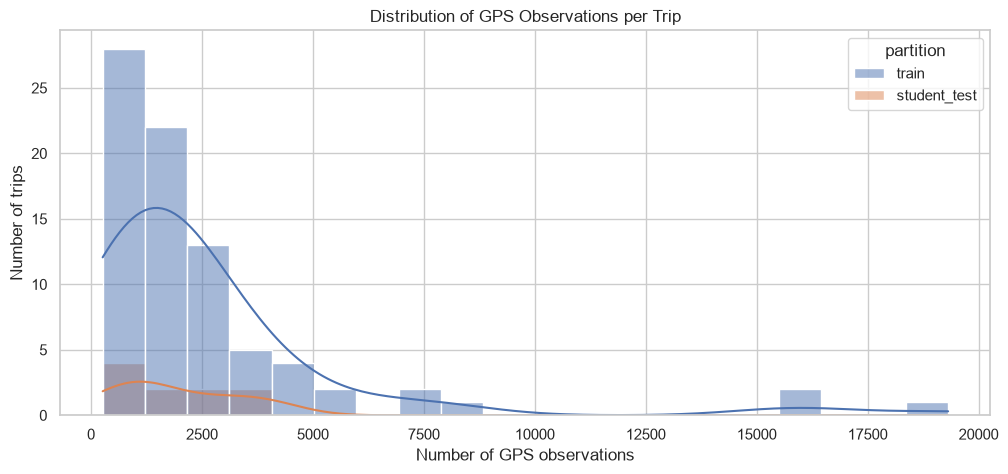

In [97]:

plt.figure(figsize=(12, 5))

sns.histplot(
    data=inventory_df,
    x="gps_observations",
    hue="partition",
    bins=20,
    kde=True
)

plt.title("Distribution of GPS Observations per Trip")
plt.xlabel("Number of GPS observations")
plt.ylabel("Number of trips")

plt.show()


In [98]:

AUDIT_DIR = PROJECT_ROOT / "results" / "preprocessing"
AUDIT_DIR.mkdir(parents=True, exist_ok=True)

inventory_df.to_csv(
    AUDIT_DIR / "dataset_inventory.csv",
    index=False
)

print("Dataset inventory saved!")


Dataset inventory saved!
